# **Importing the necessary libraries**

In [1]:
import warnings
warnings.filterwarnings('ignore')
from tensorflow import keras
from keras.layers import Input, Lambda, Dense, Flatten
from keras.models import Model
from keras.applications.vgg16 import VGG16
from keras.applications.vgg16 import preprocess_input
from keras.preprocessing import image
from keras.preprocessing.image import ImageDataGenerator
from keras.models import Sequential
import numpy as np
from glob import glob
import matplotlib.pyplot as plt

**Mounting the Google drive**

In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


**unzip dataset**

In [ ]:
%cd /content/drive/MyDrive/Pneumoniadataset/
!unzip /content/drive/MyDrive/chest_xraydataset.zip -d .


Streaming output truncated to the last 5000 lines.
  inflating: ./chest_xray dataset/chest_xray/train/NORMAL/IM-0439-0001.jpeg  
  inflating: ./chest_xray dataset/chest_xray/train/NORMAL/IM-0440-0001.jpeg  
  inflating: ./chest_xray dataset/chest_xray/train/NORMAL/IM-0441-0001.jpeg  
  inflating: ./chest_xray dataset/chest_xray/train/NORMAL/IM-0442-0001.jpeg  
  inflating: ./chest_xray dataset/chest_xray/train/NORMAL/IM-0444-0001.jpeg  
  inflating: ./chest_xray dataset/chest_xray/train/NORMAL/IM-0445-0001.jpeg  
  inflating: ./chest_xray dataset/chest_xray/train/NORMAL/IM-0446-0001.jpeg  
  inflating: ./chest_xray dataset/chest_xray/train/NORMAL/IM-0447-0001.jpeg  
  inflating: ./chest_xray dataset/chest_xray/train/NORMAL/IM-0448-0001.jpeg  
  inflating: ./chest_xray dataset/chest_xray/train/NORMAL/IM-0449-0001.jpeg  
  inflating: ./chest_xray dataset/chest_xray/train/NORMAL/IM-0450-0001.jpeg  
  inflating: ./chest_xray dataset/chest_xray/train/NORMAL/IM-0451-0001.jpeg  
  inflating: 

**Data preprocessing**

**symptoms.csv**

In [8]:
import pandas as pd
df = pd.read_csv("/content/drive/MyDrive/chest_xray/pneumonia_symptoms.csv")
df.head()

,Dieses,Symptom 1,Symptom 2,Symptom 3,Symptom 4
0,Pneumonia,Cough with phlegm,Fever,Shortness of breath,Chest pain
1,Pneumonia,Cough with phlegm,Fever,Shortness of breath,Chest pain
2,Pneumonia,Cough with phlegm,Fever,Shortness of breath,Chest pain
3,Pneumonia,Cough with phlegm,Fever,Shortness of breath,Chest pain
4,Pneumonia,Cough with phlegm,Fever,Shortness of breath,Chest pain


In [3]:
#Resizing Images to 224
IMAGE_SIZE = [224, 224]

train_path = '/content/drive/MyDrive/chest_xray/train'
valid_path = '/content/drive/MyDrive/chest_xray/val'

**training the VGG16 model**

In [4]:
vgg = VGG16(input_shape=IMAGE_SIZE + [3], weights='imagenet', include_top=False)
for layer in vgg.layers:
    layer.trainable = False
    folders = glob('/content/drive/MyDrive/chest_xray/train/*')
x = Flatten()(vgg.output)
prediction = Dense(len(folders), activation='softmax')(x)
# create a model object
model = Model(inputs=vgg.input, outputs=prediction)
# view the structure of the model
model.summary()

58889256/58889256 [==============================] - 0s 0us/step
Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 block1_conv1 (Conv2D)       (None, 224, 224, 64)      1792      
                                                                 
 block1_conv2 (Conv2D)       (None, 224, 224, 64)      36928     
                                                                 
 block1_pool (MaxPooling2D)  (None, 112, 112, 64)      0         
                                                                 
 block2_conv1 (Conv2D)       (None, 112, 112, 128)     73856     
                                                                 
 block2_conv2 (Conv2D)       (None, 112, 112, 128)     147584    
                                                              

**compiling the model**

In [5]:
model.compile(
  loss='categorical_crossentropy',
  optimizer='adam',
  metrics=['accuracy']
)

**Image Data generator**

In [6]:
from keras.preprocessing.image import ImageDataGenerator
train_datagen = ImageDataGenerator(rescale = 1./255,
                                   shear_range = 0.2,
                                   zoom_range = 0.2,
                                   horizontal_flip = True)

test_datagen = ImageDataGenerator(rescale = 1./255)




# Make sure you provide the same target size as initialied for the image size
training_set = train_datagen.flow_from_directory('/content/drive/MyDrive/chest_xray/train',
                                                 target_size = (224, 224),
                                                 batch_size = 10,
                                                 class_mode = 'categorical')




test_set = test_datagen.flow_from_directory('/content/drive/MyDrive/chest_xray/test',
                                            target_size = (224, 224),
                                            batch_size = 10,
                                            class_mode = 'categorical')




Found 5216 images belonging to 2 classes.
Found 624 images belonging to 2 classes.


# **Model Training, Loss and accuracy curves and ROC**

Epoch 1/30
522/522 [==============================] - 960s 2s/step - loss: 0.1862 - accuracy: 0.9327 - val_loss: 0.7917 - val_accuracy: 0.8173
Epoch 2/30
522/522 [==============================] - 138s 265ms/step - loss: 0.1571 - accuracy: 0.9553 - val_loss: 0.5771 - val_accuracy: 0.8974
Epoch 3/30
522/522 [==============================] - 141s 271ms/step - loss: 0.1343 - accuracy: 0.9584 - val_loss: 0.4053 - val_accuracy: 0.9167
Epoch 4/30
522/522 [==============================] - 137s 263ms/step - loss: 0.1219 - accuracy: 0.9653 - val_loss: 0.3781 - val_accuracy: 0.8894
Epoch 5/30
522/522 [==============================] - 140s 269ms/step - loss: 0.1246 - accuracy: 0.9645 - val_loss: 0.8720 - val_accuracy: 0.8638
Epoch 6/30
522/522 [==============================] - 140s 269ms/step - loss: 0.1231 - accuracy: 0.9651 - val_loss: 1.0607 - val_accuracy: 0.8622
Epoch 7/30
522/522 [==============================] - 137s 263ms/step - loss: 0.1194 - accuracy: 0.9676 - val_loss: 0.5677 - va

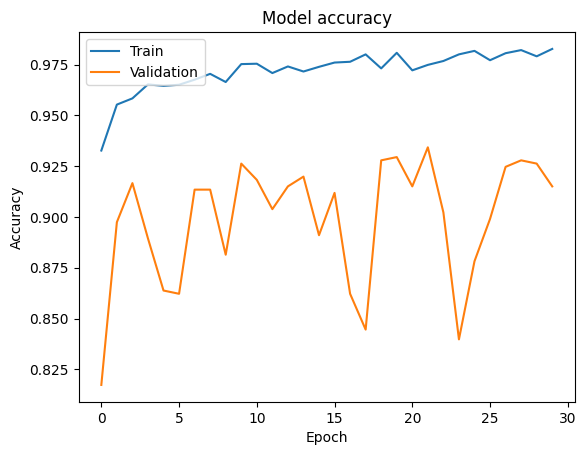

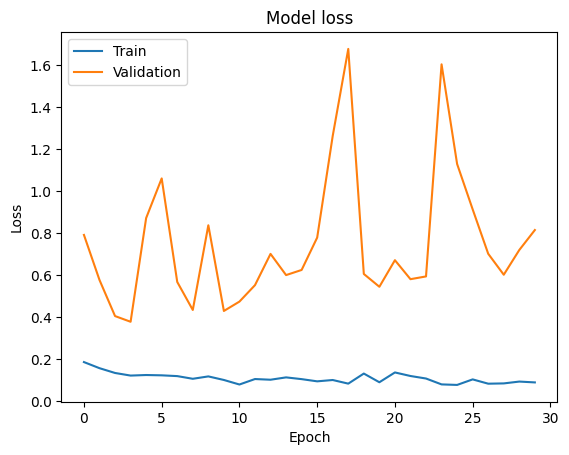

63/63 [==============================] - 7s 112ms/step


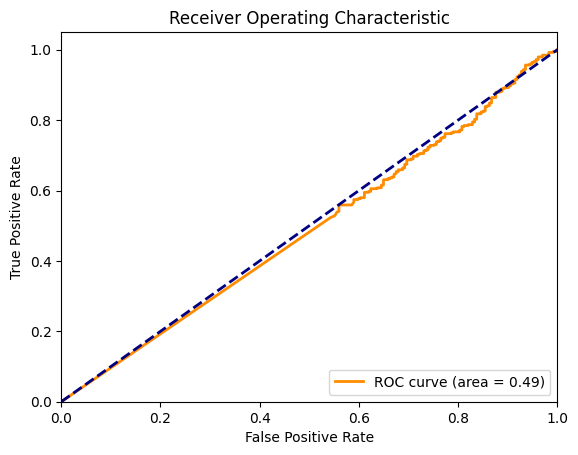

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc

# Train your model
minemodel = model.fit_generator(
    training_set,
    validation_data=test_set,
    epochs=30,
    steps_per_epoch=len(training_set),
    validation_steps=len(test_set)
)

# Plot training & validation accuracy values
plt.plot(minemodel.history['accuracy'])
plt.plot(minemodel.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

# Plot training & validation loss values
plt.plot(minemodel.history['loss'])
plt.plot(minemodel.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

# Plot ROC curve
y_pred = model.predict(test_set)
fpr, tpr, thresholds = roc_curve(test_set.classes, y_pred[:, 1])
roc_auc = auc(fpr, tpr)

plt.figure()
lw = 2
plt.plot(fpr, tpr, color='darkorange',
         lw=lw, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=lw, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

**confusion matrix**

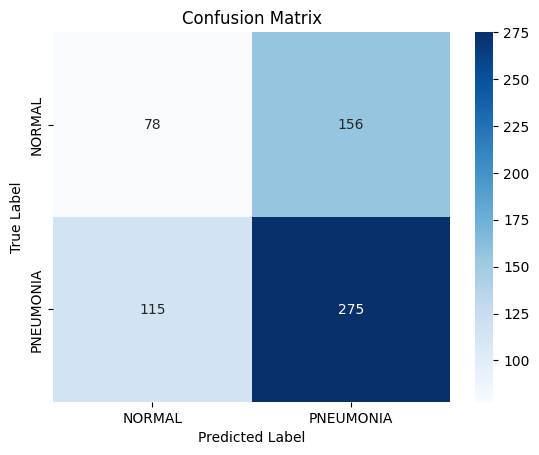

In [12]:
from sklearn.metrics import confusion_matrix

# Get the confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Create a dataframe from the confusion matrix
cm_df = pd.DataFrame(cm, columns=test_set.class_indices, index=test_set.class_indices)

# Plot the confusion matrix using seaborn
sns.heatmap(cm_df, annot=True, fmt=".0f", cmap="Blues")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

**saving the models weights**

In [9]:
import tensorflow as tf
from keras.models import load_model

model.save('/content/drive/MyDrive/chest_xray/tunedmodel.h5')

In [ ]:
from keras.models import load_model
from keras.preprocessing import image
from keras.applications.vgg16 import preprocess_input
import numpy as np

In [ ]:
model=load_model('/content/drive/MyDrive/chest_xray/tunedmodel.h5')

1/1 [==============================] - 1s 1s/step


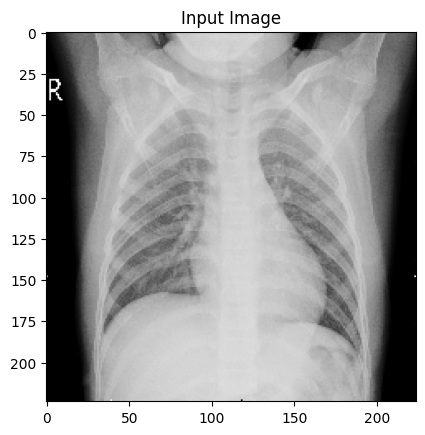

PNEUMONIA


In [ ]:
img=image.load_img('/content/drive/MyDrive/chest_xray/val/NORMAL/NORMAL2-IM-1427-0001.jpeg',target_size=(224,224))
x=image.img_to_array(img)
x=np.expand_dims(x, axis=0)
img_data=preprocess_input(x)
classes=model.predict(img_data)
result=int(classes[0][0])
plt.imshow(img)
plt.title('Input Image')
plt.show()
if result==0:
    print("PNEUMONIA")
else:
    print("Normal")

1/1 [==============================] - 0s 17ms/step


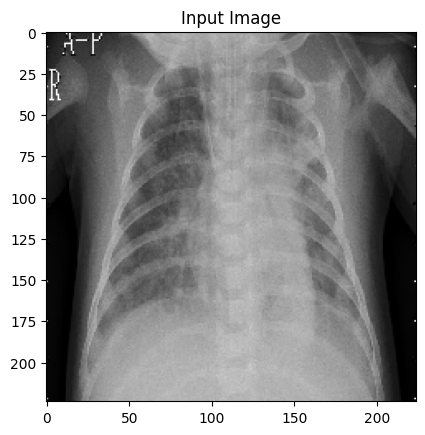

PNEUMONIA


In [ ]:
img=image.load_img('/content/drive/MyDrive/chest_xray/val/PNEUMONIA/person1946_bacteria_4874.jpeg',target_size=(224,224))
x=image.img_to_array(img)
x=np.expand_dims(x, axis=0)
img_data=preprocess_input(x)
classes=model.predict(img_data)
result=int(classes[0][0])
plt.imshow(img)
plt.title('Input Image')
plt.show()
if result==0:
    print("PNEUMONIA")
else:
    print("Normal")